# B2 – Pembentukan Citra dan Ruang Warna

**Proyek:** SIMUTEH – Sistem Identifikasi Kondisi Daun Teh

## Tujuan Praktikum
1. Memahami pembentukan citra digital dan ruang warna.
2. Memisahkan citra ke kanal B, G, R, Gray, H, S, dan V.
3. Menghitung Kontras Bercak (KB) setiap kanal.
4. Menganalisis pengaruh sampling dan kuantisasi.
5. Menentukan kanal warna yang paling sesuai untuk membedakan bercak daun teh.


In [2]:
import os

print("Lokasi saat ini:", os.getcwd())
print("Isi folder:", os.listdir())

Lokasi saat ini: /content
Isi folder: ['.config', 'sample_data']


In [3]:
import os

print("Folder src tersedia:", os.path.exists("src"))
print("File utils_cv.py tersedia:", os.path.exists("src/utils_cv.py"))

Folder src tersedia: False
File utils_cv.py tersedia: False


In [4]:
import os

os.makedirs("src", exist_ok=True)
os.makedirs("data/sintetis/citra", exist_ok=True)
os.makedirs("data/sintetis/mask_daun", exist_ok=True)
os.makedirs("data/sintetis/mask_bercak", exist_ok=True)
os.makedirs("hasil", exist_ok=True)

print("Folder proyek berhasil dibuat!")

Folder proyek berhasil dibuat!


In [5]:
%%writefile src/utils_cv.py

import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {path}")
    return img

def tampil(daftar, judul=None, baris=1, ukuran=(12, 5)):
    jumlah = len(daftar)
    kolom = int(np.ceil(jumlah / baris))

    plt.figure(figsize=ukuran)

    for i, img in enumerate(daftar):
        plt.subplot(baris, kolom, i + 1)

        if len(img.shape) == 3:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.imshow(img)
        else:
            plt.imshow(img, cmap="gray")

        if judul:
            plt.title(judul[i])

        plt.axis("off")

    plt.tight_layout()
    plt.show()

def kontras_bercak(gray, mask_daun, mask_bercak):
    daun_sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    if not np.any(daun_sehat) or not np.any(bercak):
        return 0.0

    nilai_sehat = np.mean(gray[daun_sehat])
    nilai_bercak = np.mean(gray[bercak])

    return abs(nilai_bercak - nilai_sehat)

def statistik(gray):
    return {
        "mean": np.mean(gray),
        "std": np.std(gray),
        "min": np.min(gray),
        "max": np.max(gray)
    }

Writing src/utils_cv.py


In [6]:
import sys
sys.path.append("src")

from utils_cv import baca, tampil, kontras_bercak

print("Berhasil! utils_cv sudah bisa digunakan.")

Berhasil! utils_cv sudah bisa digunakan.


In [7]:
from google.colab import files

uploaded = files.upload()

Saving dataset_simuteh.zip to dataset_simuteh.zip


In [9]:
import zipfile
import os

with zipfile.ZipFile("dataset_simuteh.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("Jumlah citra:", len(os.listdir("data/sintetis/citra")))

Jumlah citra: 60


In [10]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("src")

from utils_cv import baca, tampil, kontras_bercak, statistik

print("Jumlah citra:", len(os.listdir("data/sintetis/citra")))
print("Folder dataset berhasil dibaca!")

Jumlah citra: 60
Folder dataset berhasil dibaca!


## 2.1 Perhitungan Ukuran Citra dan Ruang Warna

Diketahui:
- Panjang fokus kamera (f) = 4,0 mm
- Ukuran piksel sensor = 1,4 µm = 0,0014 mm
- Resolusi kamera = 4000 × 3000 piksel
- Diameter minimum bercak (X) = 5 mm
- Jarak kamera (Z) = 300 mm
- RGB bercak = (196, 178, 86)
- RGB daun sehat = (52, 136, 60)

A. Menghitung ukuran bercak pada sensor

In [11]:
f = 4.0
X = 5.0
Z = 300
pixel_sensor = 0.0014

x = (f * X) / Z
jumlah_pixel = x / pixel_sensor

print("Ukuran bercak pada sensor:", x, "mm")
print("Ukuran bercak dalam piksel:", jumlah_pixel, "piksel")

Ukuran bercak pada sensor: 0.06666666666666667 mm
Ukuran bercak dalam piksel: 47.61904761904762 piksel


B. Menghitung pada jarak 600 mm

In [12]:
Z2 = 600

x2 = (f * X) / Z2
pixel2 = x2 / pixel_sensor

print("Ukuran bercak pada sensor:", x2, "mm")
print("Ukuran bercak dalam piksel:", pixel2, "piksel")

Ukuran bercak pada sensor: 0.03333333333333333 mm
Ukuran bercak dalam piksel: 23.80952380952381 piksel


C. Jarak maksimum agar bercak minimal 10 piksel

In [13]:
target_pixel = 10

ukuran_sensor = target_pixel * pixel_sensor
jarak_maksimum = (f * X) / ukuran_sensor

print("Jarak maksimum:", jarak_maksimum, "mm")
print("Dalam meter:", jarak_maksimum / 1000, "m")

Jarak maksimum: 1428.5714285714284 mm
Dalam meter: 1.4285714285714284 m


D. Perhitungan setelah gambar diperkecil menjadi 640 piksel

In [14]:
skala = 640 / 4000

pixel_resize = jumlah_pixel * skala
pixel_awal = target_pixel / skala

ukuran_sensor_resize = pixel_awal * pixel_sensor
jarak_resize = (f * X) / ukuran_sensor_resize

print("Skala pengecilan:", skala)
print("Ukuran bercak setelah resize:", pixel_resize, "piksel")
print("Jarak maksimum:", jarak_resize, "mm")

Skala pengecilan: 0.16
Ukuran bercak setelah resize: 7.6190476190476195 piksel
Jarak maksimum: 228.57142857142858 mm


E. Menghitung kebutuhan memori citra

In [15]:
ukuran_asli = 4000 * 3000 * 3
ukuran_rgb = 640 * 480 * 3
ukuran_gray = 640 * 480

print("Foto asli:", ukuran_asli, "byte")
print("RGB 640x480:", ukuran_rgb, "byte")
print("Grayscale 640x480:", ukuran_gray, "byte")
print("300 foto asli:", ukuran_asli * 300, "byte")

Foto asli: 36000000 byte
RGB 640x480: 921600 byte
Grayscale 640x480: 307200 byte
300 foto asli: 10800000000 byte


F. Menghitung grayscale dan Hue

In [16]:
# RGB bercak dan daun sehat
bercak = np.array([196, 178, 86], dtype=np.uint8)
sehat = np.array([52, 136, 60], dtype=np.uint8)

def hitung_gray(rgb):
    r, g, b = rgb
    return 0.299*r + 0.587*g + 0.114*b

gray_bercak = hitung_gray(bercak)
gray_sehat = hitung_gray(sehat)

print("Grayscale bercak:", gray_bercak)
print("Grayscale daun sehat:", gray_sehat)
print("Selisih grayscale:", abs(gray_bercak-gray_sehat))

# OpenCV menggunakan urutan BGR
bercak_bgr = np.array([[ [86, 178, 196] ]], dtype=np.uint8)
sehat_bgr = np.array([[ [60, 136, 52] ]], dtype=np.uint8)

hsv_bercak = cv2.cvtColor(bercak_bgr, cv2.COLOR_BGR2HSV)
hsv_sehat = cv2.cvtColor(sehat_bgr, cv2.COLOR_BGR2HSV)

print("Hue bercak:", hsv_bercak[0, 0, 0])
print("Hue daun sehat:", hsv_sehat[0, 0, 0])

Grayscale bercak: 172.89399999999998
Grayscale daun sehat: 102.22
Selisih grayscale: 70.67399999999998
Hue bercak: 25
Hue daun sehat: 63


## 2.2 Rencana Akuisisi Citra

Rencana akuisisi citra disusun agar gambar daun teh memiliki kualitas dan kondisi pengambilan yang konsisten.

| Aspek | Rencana |
|---|---|
| Jarak kamera | Maksimal 22,86 cm |
| Sudut kamera | Tegak lurus terhadap objek (90°) |
| Resolusi kamera | Minimal 4000 × 3000 piksel |
| Latar belakang | Polos dan tidak memiliki pola mencolok |
| Referensi ukuran | Menggunakan penggaris sebagai skala |
| Pencahayaan | Normal, gelap, terang, kontras rendah, dan bayangan |
| Jumlah citra | 20 citra setiap kelas, dibagi ke beberapa kondisi pencahayaan |
| Format nama file | Menggunakan nomor citra dan kelas |
| Privasi | Menghindari wajah dan menghapus metadata lokasi jika ada |

Akuisisi citra perlu dilakukan secara konsisten agar perbedaan warna yang terlihat berasal dari kondisi daun dan bukan hanya akibat perubahan lingkungan pengambilan gambar.

## 2.3 Pemisahan Kanal Warna

Pada tahap ini dilakukan pemisahan citra ke dalam kanal B, G, R, Grayscale, Hue, Saturation, dan Value. Tujuannya adalah mengamati informasi warna yang dapat digunakan untuk membedakan kondisi daun teh.

A. Membaca citra

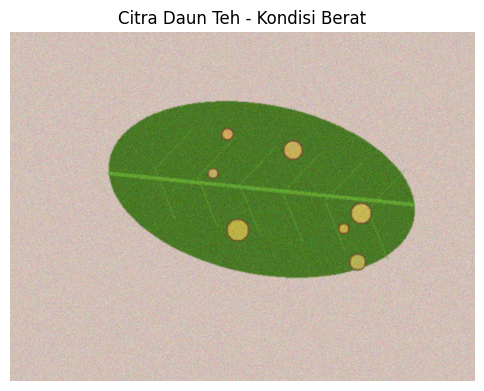

In [17]:
img = baca("data/sintetis/citra/teh_041.png")

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Citra Daun Teh - Kondisi Berat")
plt.axis("off")
plt.show()

B. Memisahkan kanal warna

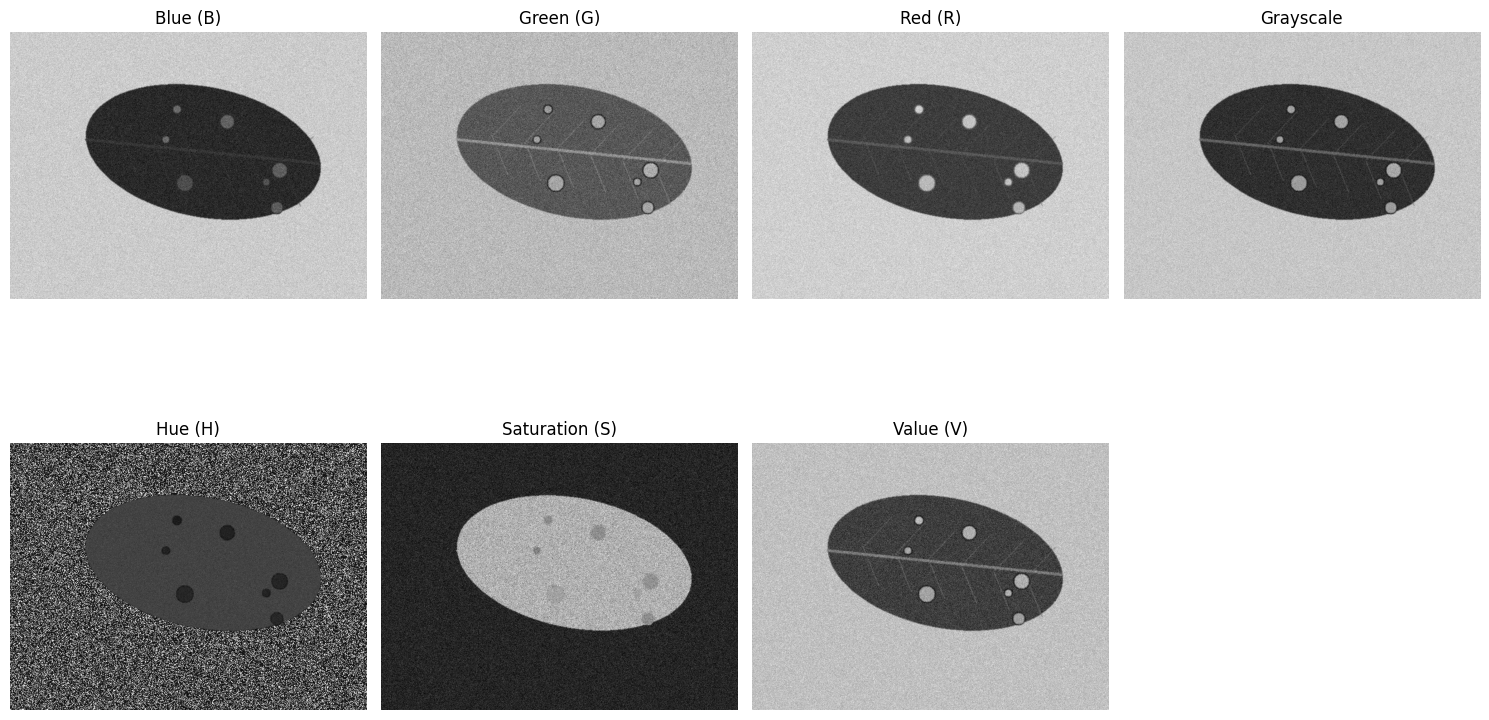

In [18]:
# Memisahkan kanal B, G, R
B, G, R = cv2.split(img)

# Mengubah ke Grayscale
Gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Mengubah ke HSV
HSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(HSV)

# Menampilkan seluruh kanal
kanal = [B, G, R, Gray, H, S, V]
judul = ["Blue (B)", "Green (G)", "Red (R)",
         "Grayscale", "Hue (H)", "Saturation (S)", "Value (V)"]

plt.figure(figsize=(15, 9))

for i in range(7):
    plt.subplot(2, 4, i + 1)
    plt.imshow(kanal[i], cmap="gray")
    plt.title(judul[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

C. Menghitung kontras bercak setiap kanal

In [19]:
mask_daun = baca("data/sintetis/mask_daun/teh_041.png")
mask_bercak = baca("data/sintetis/mask_bercak/teh_041.png")

# Mengubah mask menjadi grayscale
if len(mask_daun.shape) == 3:
    mask_daun = cv2.cvtColor(mask_daun, cv2.COLOR_BGR2GRAY)

if len(mask_bercak.shape) == 3:
    mask_bercak = cv2.cvtColor(mask_bercak, cv2.COLOR_BGR2GRAY)

mask_daun = mask_daun > 0
mask_bercak = mask_bercak > 0

hasil_kontras = {}

for nama, citra_kanal in zip(judul, kanal):
    nilai = kontras_bercak(
        citra_kanal,
        mask_daun,
        mask_bercak
    )
    hasil_kontras[nama] = nilai

for nama, nilai in hasil_kontras.items():
    print(f"{nama}: {nilai:.2f}")

Blue (B): 31.72
Green (G): 27.86
Red (R): 93.35
Grayscale: 47.88
Hue (H): 22.34
Saturation (S): 24.67
Value (V): 46.73


D. Menampilkan tabel hasil kontras

In [20]:
df_kontras = pd.DataFrame(
    hasil_kontras.items(),
    columns=["Kanal", "Kontras Bercak"]
)

df_kontras = df_kontras.sort_values(
    by="Kontras Bercak",
    ascending=False
)

display(df_kontras)

,Kanal,Kontras Bercak
2,Red (R),93.346697
3,Grayscale,47.877397
6,Value (V),46.732044
0,Blue (B),31.717903
1,Green (G),27.858015
5,Saturation (S),24.671407
4,Hue (H),22.342483


E. Menyimpan hasil

In [21]:
os.makedirs("hasil", exist_ok=True)

df_kontras.to_csv(
    "hasil/b2_kontras_teh_041.csv",
    index=False
)

print("Hasil kontras berhasil disimpan!")

Hasil kontras berhasil disimpan!


## 2.4 Sampling dan Kuantisasi Citra

Sampling merupakan proses mengubah ukuran atau resolusi citra, sedangkan kuantisasi merupakan proses mengurangi jumlah tingkat intensitas piksel. Percobaan ini dilakukan untuk mengetahui pengaruh keduanya terhadap tampilan dan kontras bercak daun teh.

A. Percobaan sampling

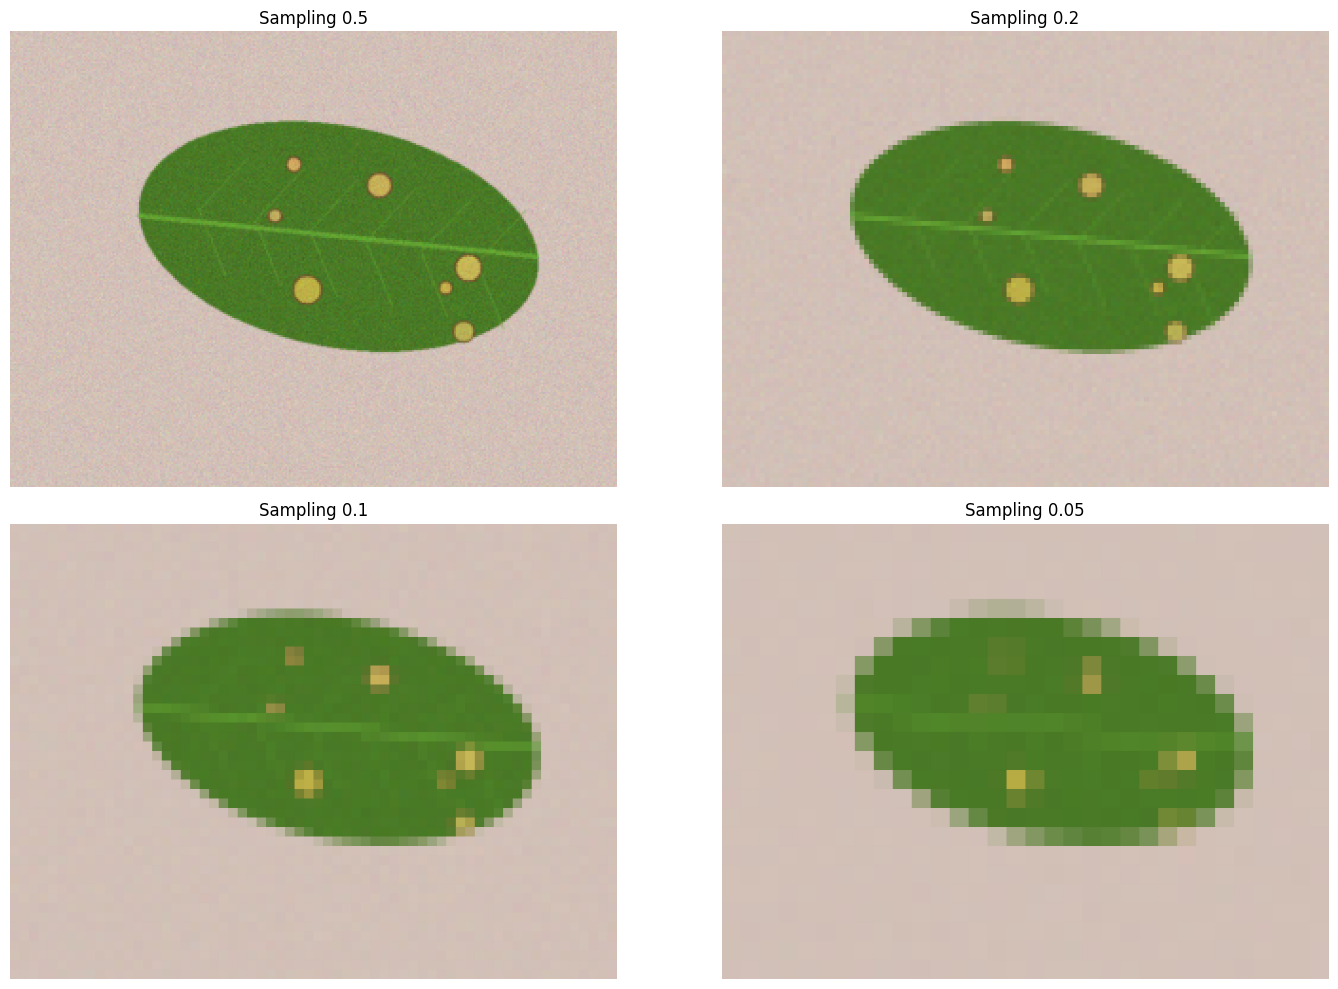

In [22]:
img = baca("data/sintetis/citra/teh_041.png")

faktor_sampling = [0.5, 0.2, 0.1, 0.05]

hasil_sampling = []

plt.figure(figsize=(15, 10))

for i, faktor in enumerate(faktor_sampling):
    tinggi = int(img.shape[0] * faktor)
    lebar = int(img.shape[1] * faktor)

    # Mengecilkan citra
    kecil = cv2.resize(img, (lebar, tinggi),
                       interpolation=cv2.INTER_AREA)

    # Mengembalikan ke ukuran awal untuk perbandingan tampilan
    kembali = cv2.resize(kecil, (img.shape[1], img.shape[0]),
                         interpolation=cv2.INTER_NEAREST)

    hasil_sampling.append({
        "Faktor": faktor,
        "Lebar": lebar,
        "Tinggi": tinggi,
        "Ukuran (KB)": kecil.nbytes / 1024
    })

    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(kembali, cv2.COLOR_BGR2RGB))
    plt.title(f"Sampling {faktor}")
    plt.axis("off")

plt.tight_layout()
plt.show()

B. Tabel hasil sampling

In [23]:
df_sampling = pd.DataFrame(hasil_sampling)
display(df_sampling)

,Faktor,Lebar,Tinggi,Ukuran (KB)
0,0.50,320,240,225.00
1,0.20,128,96,36.00
2,0.10,64,48,9.00
3,0.05,32,24,2.25


C. Percobaan kuantisasi

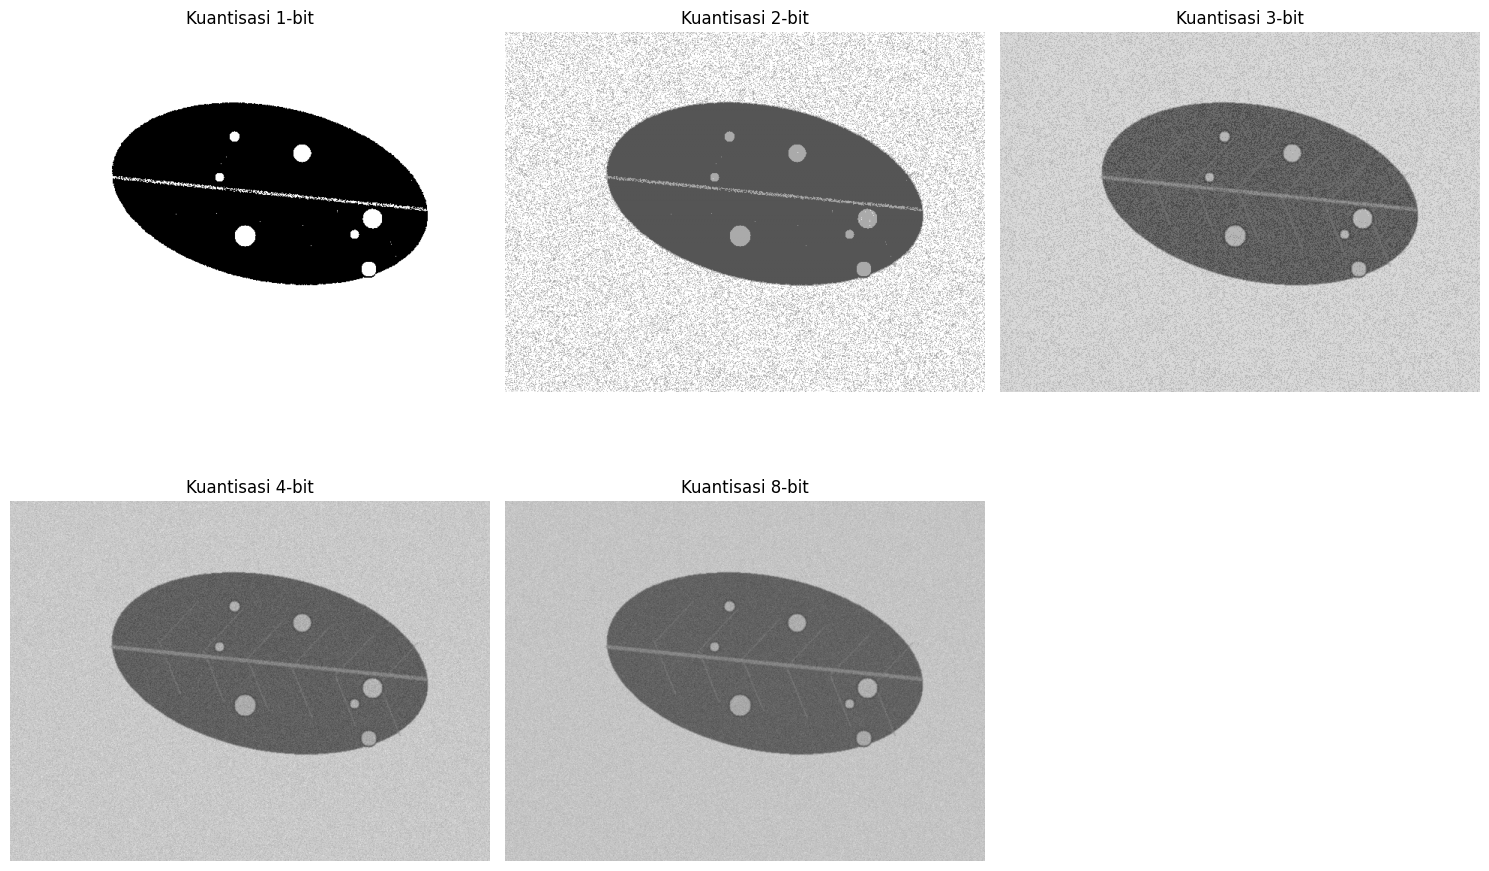

In [24]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tingkat_bit = [1, 2, 3, 4, 8]
hasil_kuantisasi = []

plt.figure(figsize=(15, 10))

for i, k in enumerate(tingkat_bit):
    jumlah_level = 2 ** k

    # Kuantisasi intensitas grayscale
    citra_q = (
        np.floor(gray.astype(np.float32) / 256 * jumlah_level)
        * (255 / (jumlah_level - 1))
    ).clip(0, 255).astype(np.uint8)

    jumlah_unik = len(np.unique(citra_q))
    ukuran_kb = citra_q.nbytes / 1024

    hasil_kuantisasi.append({
        "Bit": k,
        "Jumlah Level Maksimum": jumlah_level,
        "Jumlah Level Aktual": jumlah_unik,
        "Ukuran (KB)": ukuran_kb
    })

    plt.subplot(2, 3, i + 1)
    plt.imshow(citra_q, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Kuantisasi {k}-bit")
    plt.axis("off")

plt.tight_layout()
plt.show()

D. Menampilkan tabel hasil kuantisasi

In [25]:
df_kuantisasi = pd.DataFrame(hasil_kuantisasi)
display(df_kuantisasi)

,Bit,Jumlah Level Maksimum,Jumlah Level Aktual,Ukuran (KB)
0,1,2,2,300.0
1,2,4,3,300.0
2,3,8,6,300.0
3,4,16,11,300.0
4,8,256,164,300.0


E. Menyimpan hasil sampling dan kuantisasi

In [26]:
df_sampling.to_csv("hasil/b2_sampling.csv", index=False)
df_kuantisasi.to_csv("hasil/b2_kuantisasi.csv", index=False)

print("Hasil sampling dan kuantisasi berhasil disimpan!")

Hasil sampling dan kuantisasi berhasil disimpan!


In [27]:
label_df = pd.read_csv("data/sintetis/label.csv")

display(label_df.head())
print("Kolom dataset:", label_df.columns.tolist())

,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0


Kolom dataset: ['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']


## 2.5 Analisis Kanal pada Kelas Berat

Pada tahap ini dilakukan pengukuran kontras bercak pada 20 citra daun teh dengan kelas berat. Pengukuran dilakukan pada kanal B, G, R, Grayscale, Hue, Saturation, dan Value berdasarkan lima kondisi pencahayaan.

In [28]:
# Mengambil data kelas berat
data_berat = label_df[label_df["kelas"] == "berat"].copy()

print("Jumlah citra kelas berat:", len(data_berat))
display(data_berat)

Jumlah citra kelas berat: 20


,nama_file,kelas,kondisi_cahaya,persen_bercak
40,teh_041.png,berat,normal,4.07
41,teh_042.png,berat,gelap,3.09
42,teh_043.png,berat,terang,3.00
43,teh_044.png,berat,kontras_rendah,4.90
44,teh_045.png,berat,bayangan,6.92
45,teh_046.png,berat,normal,4.19
46,teh_047.png,berat,gelap,3.57
47,teh_048.png,berat,terang,3.65
48,teh_049.png,berat,kontras_rendah,3.73
49,teh_050.png,berat,bayangan,5.23


B. Menghitung kontras setiap kanal

In [29]:
hasil_berat = []

for _, row in data_berat.iterrows():

    nama_file = row["nama_file"]
    kondisi = row["kondisi_cahaya"]

    # Membaca citra
    img = baca(f"data/sintetis/citra/{nama_file}")

    # Membaca mask
    mask_daun = cv2.imread(
        f"data/sintetis/mask_daun/{nama_file}",
        cv2.IMREAD_GRAYSCALE
    )

    mask_bercak = cv2.imread(
        f"data/sintetis/mask_bercak/{nama_file}",
        cv2.IMREAD_GRAYSCALE
    )

    if mask_daun is None or mask_bercak is None:
        print("Mask tidak ditemukan:", nama_file)
        continue

    # Memisahkan kanal
    B, G, R = cv2.split(img)
    Gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    HSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    H, S, V = cv2.split(HSV)

    kanal = {
        "B": B,
        "G": G,
        "R": R,
        "Gray": Gray,
        "H": H,
        "S": S,
        "V": V
    }

    hasil = {
        "nama_file": nama_file,
        "kondisi_cahaya": kondisi
    }

    for nama_kanal, citra_kanal in kanal.items():
        hasil[nama_kanal] = kontras_bercak(
            citra_kanal,
            mask_daun,
            mask_bercak
        )

    hasil_berat.append(hasil)

df_berat = pd.DataFrame(hasil_berat)

display(df_berat.head())
print("Jumlah citra yang berhasil dianalisis:", len(df_berat))

,nama_file,kondisi_cahaya,B,G,R,Gray,H,S,V
0,teh_041.png,normal,31.717903,27.858015,93.346697,47.877397,22.342483,24.671407,46.732044
1,teh_042.png,gelap,16.708927,10.777244,110.086069,41.144833,35.926491,30.321565,43.072985
2,teh_043.png,terang,24.634938,10.616869,69.953258,29.950204,25.305024,11.276483,24.706229
3,teh_044.png,kontras_rendah,3.968339,6.215740,38.989298,15.752091,26.030675,3.533661,15.841833
4,teh_045.png,bayangan,19.983972,11.414001,66.301222,28.799878,23.832555,28.639395,27.123102


Jumlah citra yang berhasil dianalisis: 20


C. Menghitung rata-rata berdasarkan kondisi cahaya

In [30]:
tabel_berat = df_berat.groupby("kondisi_cahaya")[
    ["B", "G", "R", "Gray", "H", "S", "V"]
].mean()

urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel_berat = tabel_berat.reindex(urutan_cahaya)

display(tabel_berat.round(2))

,B,G,R,Gray,H,S,V
kondisi_cahaya,,,,,,,
normal,23.26,16.40,105.20,43.73,29.96,20.10,35.25
gelap,14.17,18.90,105.52,44.27,33.88,26.20,44.02
terang,15.60,6.21,76.71,27.89,31.64,9.88,18.20
kontras_rendah,6.56,4.50,38.78,14.98,24.55,3.92,15.05
bayangan,19.72,9.48,77.61,30.95,28.69,26.88,24.85


D. Menyimpan hasil ke CSV

In [31]:
os.makedirs("hasil", exist_ok=True)

tabel_berat.to_csv("hasil/b2_kb_kanal.csv")

df_berat.to_csv(
    "hasil/b2_detail_kanal_kelas_berat.csv",
    index=False
)

print("Hasil analisis kelas berat berhasil disimpan!")

Hasil analisis kelas berat berhasil disimpan!


In [32]:
data_ringan = label_df[
    label_df["kelas"] == "ringan"
].copy()

print("Jumlah citra kelas ringan:", len(data_ringan))
display(data_ringan)

Jumlah citra kelas ringan: 20


,nama_file,kelas,kondisi_cahaya,persen_bercak
20,teh_021.png,ringan,normal,0.42
21,teh_022.png,ringan,gelap,0.65
22,teh_023.png,ringan,terang,0.66
23,teh_024.png,ringan,kontras_rendah,0.60
24,teh_025.png,ringan,bayangan,0.38
25,teh_026.png,ringan,normal,0.43
26,teh_027.png,ringan,gelap,0.73
27,teh_028.png,ringan,terang,0.76
28,teh_029.png,ringan,kontras_rendah,0.40
29,teh_030.png,ringan,bayangan,0.19


A. Menghitung kontras setiap kanal

In [33]:
hasil_ringan = []

for _, row in data_ringan.iterrows():

    nama_file = row["nama_file"]
    kondisi = row["kondisi_cahaya"]

    img = baca(f"data/sintetis/citra/{nama_file}")

    mask_daun = cv2.imread(
        f"data/sintetis/mask_daun/{nama_file}",
        cv2.IMREAD_GRAYSCALE
    )

    mask_bercak = cv2.imread(
        f"data/sintetis/mask_bercak/{nama_file}",
        cv2.IMREAD_GRAYSCALE
    )

    if mask_daun is None or mask_bercak is None:
        print("Mask tidak ditemukan:", nama_file)
        continue

    B, G, R = cv2.split(img)
    Gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    HSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    H, S, V = cv2.split(HSV)

    kanal = {
        "B": B,
        "G": G,
        "R": R,
        "Gray": Gray,
        "H": H,
        "S": S,
        "V": V
    }

    hasil = {
        "nama_file": nama_file,
        "kondisi_cahaya": kondisi
    }

    for nama_kanal, citra_kanal in kanal.items():
        hasil[nama_kanal] = kontras_bercak(
            citra_kanal,
            mask_daun,
            mask_bercak
        )

    hasil_ringan.append(hasil)

df_ringan = pd.DataFrame(hasil_ringan)

print("Jumlah citra berhasil dianalisis:", len(df_ringan))
display(df_ringan.head())

Jumlah citra berhasil dianalisis: 20


,nama_file,kondisi_cahaya,B,G,R,Gray,H,S,V
0,teh_021.png,normal,19.558918,7.812024,86.192297,32.587482,26.417858,20.533548,21.339590
1,teh_022.png,gelap,3.870078,6.070316,72.668585,18.595261,28.192424,17.801119,9.965390
2,teh_023.png,terang,1.638001,7.949127,60.109273,13.106820,30.834247,3.653263,6.385709
3,teh_024.png,kontras_rendah,7.564729,3.505591,31.781021,8.292235,27.155706,7.981643,5.685750
4,teh_025.png,bayangan,0.999963,33.506452,47.682083,5.311576,32.921723,29.287585,20.522352


B. Menghitung rata-rata berdasarkan pencahayaan

In [34]:
tabel_ringan = df_ringan.groupby("kondisi_cahaya")[
    ["B", "G", "R", "Gray", "H", "S", "V"]
].mean()

urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel_ringan = tabel_ringan.reindex(urutan_cahaya)

display(tabel_ringan.round(2))

,B,G,R,Gray,H,S,V
kondisi_cahaya,,,,,,,
normal,24.50,8.65,91.13,35.12,27.69,25.13,28.29
gelap,7.61,8.93,81.61,27.08,33.78,24.12,24.13
terang,11.75,5.99,67.61,17.68,30.97,12.56,7.61
kontras_rendah,5.82,3.51,30.75,7.79,22.33,7.08,5.89
bayangan,7.43,20.43,48.33,12.99,28.25,27.64,20.05


C. Menyimpan hasil

In [35]:
tabel_ringan.to_csv(
    "hasil/b2_kb_kanal_ringan.csv"
)

df_ringan.to_csv(
    "hasil/b2_detail_kanal_kelas_ringan.csv",
    index=False
)

print("Hasil analisis kelas ringan berhasil disimpan!")

Hasil analisis kelas ringan berhasil disimpan!


8. Menentukan Kanal Terbaik

In [36]:
def analisis_kanal_terbaik(nama_file):

    img = baca(f"data/sintetis/citra/{nama_file}")

    mask_daun = cv2.imread(
        f"data/sintetis/mask_daun/{nama_file}",
        cv2.IMREAD_GRAYSCALE
    )

    mask_bercak = cv2.imread(
        f"data/sintetis/mask_bercak/{nama_file}",
        cv2.IMREAD_GRAYSCALE
    )

    B, G, R = cv2.split(img)
    Gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    HSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    H, S, V = cv2.split(HSV)

    kanal = {
        "B": B, "G": G, "R": R,
        "Gray": Gray, "H": H, "S": S, "V": V
    }

    nilai_kontras = {
        nama: kontras_bercak(citra, mask_daun, mask_bercak)
        for nama, citra in kanal.items()
    }

    terbaik = max(nilai_kontras, key=nilai_kontras.get)

    print(f"\nGambar: {nama_file}")
    print("Kanal terbaik:", terbaik)
    print("Nilai kontras:", round(nilai_kontras[terbaik], 2))

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Citra Asli {nama_file}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(kanal[terbaik], cmap="gray")
    plt.title(f"Kanal Terbaik: {terbaik}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    return terbaik, nilai_kontras


terbaik_021 = analisis_kanal_terbaik("teh_021.png")
terbaik_045 = analisis_kanal_terbaik("teh_045.png")

Output hidden; open in https://colab.research.google.com to view.


Gambar: teh_045.png
Kanal terbaik: R
Nilai kontras: 66.3


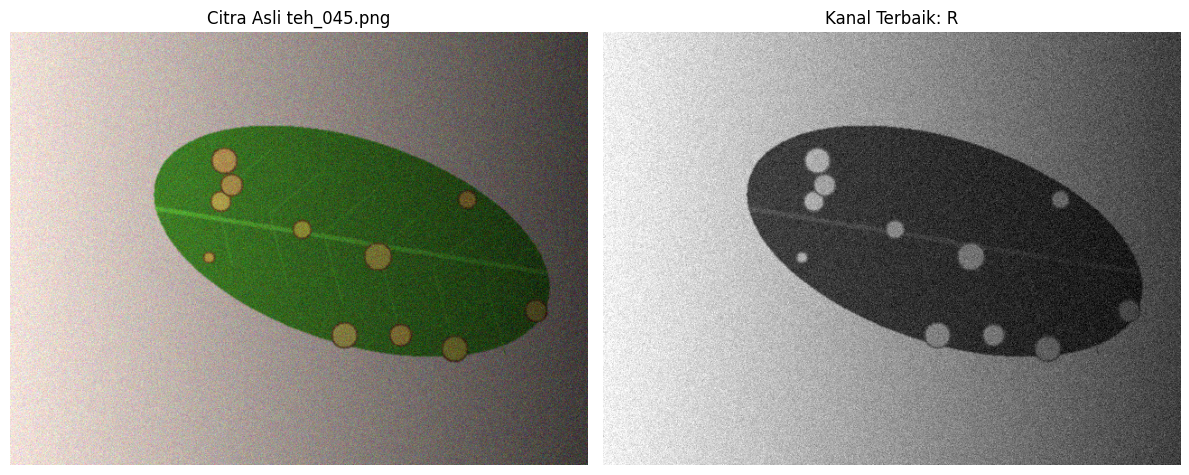

In [44]:
terbaik_045 = analisis_kanal_terbaik("teh_045.png")

In [45]:
# Membuat tabel hasil kanal terbaik
hasil_kanal_terbaik = pd.DataFrame([
    {
        "nama_file": "teh_021.png",
        "kelas": "ringan",
        "kanal_terbaik": terbaik_021[0],
        "nilai_kontras": terbaik_021[1][terbaik_021[0]]
    },
    {
        "nama_file": "teh_045.png",
        "kelas": "berat",
        "kanal_terbaik": terbaik_045[0],
        "nilai_kontras": terbaik_045[1][terbaik_045[0]]
    }
])

display(hasil_kanal_terbaik)

hasil_kanal_terbaik.to_csv(
    "hasil/b2_kanal_terbaik.csv",
    index=False
)

,nama_file,kelas,kanal_terbaik,nilai_kontras
0,teh_021.png,ringan,R,86.192297
1,teh_045.png,berat,R,66.301222


9. Menyimpan seluruh hasil B2

In [37]:
import os
import shutil

os.makedirs("hasil", exist_ok=True)

# Membuat ZIP hasil praktikum B2
shutil.make_archive(
    "/content/hasil_B2_SIMUTEH",
    "zip",
    root_dir="/content/hasil"
)

print("Seluruh hasil B2 berhasil dikemas!")

Seluruh hasil B2 berhasil dikemas!


1. Tampilkan tabel rata-rata kelas ringan


In [38]:
tabel_ringan = df_ringan.groupby("kondisi_cahaya")[
    ["B", "G", "R", "Gray", "H", "S", "V"]
].mean()

urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel_ringan = tabel_ringan.reindex(urutan_cahaya)

display(tabel_ringan.round(2))

,B,G,R,Gray,H,S,V
kondisi_cahaya,,,,,,,
normal,24.50,8.65,91.13,35.12,27.69,25.13,28.29
gelap,7.61,8.93,81.61,27.08,33.78,24.12,24.13
terang,11.75,5.99,67.61,17.68,30.97,12.56,7.61
kontras_rendah,5.82,3.51,30.75,7.79,22.33,7.08,5.89
bayangan,7.43,20.43,48.33,12.99,28.25,27.64,20.05


2. Tampilkan kanal terbaik

In [39]:
terbaik_021 = analisis_kanal_terbaik("teh_021.png")
terbaik_045 = analisis_kanal_terbaik("teh_045.png")

Output hidden; open in https://colab.research.google.com to view.

In [40]:
tabel_berat.to_csv("hasil/b2_kb_kanal_berat.csv")
tabel_ringan.to_csv("hasil/b2_kb_kanal_ringan.csv")

df_berat.to_csv("hasil/b2_detail_kanal_kelas_berat.csv", index=False)
df_ringan.to_csv("hasil/b2_detail_kanal_kelas_ringan.csv", index=False)

print("Seluruh hasil B2 berhasil disimpan!")

Seluruh hasil B2 berhasil disimpan!


1. Buat Tabel 8

In [41]:
# Menggabungkan hasil analisis kelas ringan dan berat
df_gabungan = pd.concat([df_berat, df_ringan], ignore_index=True)

# Menghitung rata-rata kontras setiap kanal berdasarkan kondisi cahaya
tabel_8 = df_gabungan.groupby("kondisi_cahaya")[
    ["B", "G", "R", "Gray", "H", "S", "V"]
].mean()

# Mengurutkan kondisi cahaya
urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel_8 = tabel_8.reindex(urutan_cahaya)

# Menampilkan Tabel 8
print("Tabel 8. Format rerata KB per kanal dan kondisi cahaya")
display(tabel_8.round(2))

Tabel 8. Format rerata KB per kanal dan kondisi cahaya


,B,G,R,Gray,H,S,V
kondisi_cahaya,,,,,,,
normal,23.88,12.52,98.16,39.43,28.82,22.61,31.77
gelap,10.89,13.92,93.57,35.67,33.83,25.16,34.07
terang,13.68,6.10,72.16,22.79,31.31,11.22,12.90
kontras_rendah,6.19,4.00,34.76,11.39,23.44,5.50,10.47
bayangan,13.58,14.95,62.97,21.97,28.47,27.26,22.45


In [42]:
tabel_8.to_csv("hasil/b2_tabel_8.csv")

print("Tabel 8 berhasil disimpan!")

Tabel 8 berhasil disimpan!


In [43]:
from google.colab import files

files.download("hasil/b2_tabel_8.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
tabel_ringan = df_ringan.groupby("kondisi_cahaya")[
    ["B", "G", "R", "Gray", "H", "S", "V"]
].mean()

urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel_ringan = tabel_ringan.reindex(urutan_cahaya)

print("Rerata KB Kelas Ringan")
display(tabel_ringan.round(2))

tabel_ringan.to_csv(
    "hasil/b2_kb_kanal_ringan.csv"
)

Rerata KB Kelas Ringan


,B,G,R,Gray,H,S,V
kondisi_cahaya,,,,,,,
normal,24.50,8.65,91.13,35.12,27.69,25.13,28.29
gelap,7.61,8.93,81.61,27.08,33.78,24.12,24.13
terang,11.75,5.99,67.61,17.68,30.97,12.56,7.61
kontras_rendah,5.82,3.51,30.75,7.79,22.33,7.08,5.89
bayangan,7.43,20.43,48.33,12.99,28.25,27.64,20.05


P2.1 Rekomendasi Jarak Pemotretan dan Resolusi Minimum

Berdasarkan hasil perhitungan, ukuran bercak minimum 5 mm membutuhkan sekitar 47,62 piksel pada jarak 30 cm. Setelah citra diperkecil menjadi 640 × 480 piksel, ukuran bercak menjadi sekitar 7,62 piksel. Oleh karena itu, pengambilan citra disarankan menggunakan kamera dengan resolusi minimal 4000 × 3000 piksel pada jarak maksimal sekitar 22,86 cm agar bercak kecil tetap dapat terdeteksi dengan baik.

P2.2 Kanal dengan KB Tertinggi

Berdasarkan hasil pengujian pada kelas ringan dan kelas berat, kanal R (Red) memberikan nilai KB tertinggi secara konsisten pada seluruh kondisi cahaya. Hal ini karena daun sehat berwarna hijau sehingga intensitas kanal merah relatif rendah, sedangkan bercak berwarna kekuningan hingga kecokelatan memiliki komponen merah lebih tinggi sehingga perbedaannya tampak lebih jelas pada kanal R.

P2.3 Perbandingan Kanal H dan V

Kondisi Cahaya	H Ringan	V Ringan	H Berat	V Berat
Gelap	33,78	24,13	33,88	44,02
Terang	30,97	7,61	31,64	18,20
Bayangan	28,25	20,05	28,69	24,85

Analisis:

Berdasarkan tabel, kanal H memiliki nilai KB lebih tinggi daripada kanal V pada kondisi terang dan bayangan, baik pada kelas ringan maupun berat. Namun, pada kondisi gelap kelas berat, kanal V memiliki nilai KB lebih tinggi, yaitu 44,02 dibandingkan kanal H sebesar 33,88.

Dengan demikian, hasil pengujian menunjukkan bahwa kanal H cukup tahan terhadap perubahan cahaya, tetapi tidak selalu lebih unggul daripada kanal V pada semua kondisi.

Catatan: KB adalah kontras bercak. Nilai lebih tinggi menunjukkan perbedaan intensitas antara area daun sehat dan bercak yang lebih besar.

P2.4 Pengaruh Kuantisasi

Nilai KB yang tinggi pada jumlah bit kecil tidak selalu berarti kualitas citra lebih baik. Kuantisasi mengurangi jumlah tingkat intensitas sehingga detail bercak dapat hilang walaupun perbedaan intensitas masih terlihat. Oleh karena itu, penilaian kualitas citra perlu mempertimbangkan tampilan visual selain nilai KB.

P2.5 Pengaruh Sampling

Bercak mulai sulit dibedakan ketika faktor sampling sekitar 0,2 atau lebih kecil karena ukuran bercak mendekati sekitar 10 piksel. Hal ini sesuai dengan hasil perhitungan butir 2.1(d) yang menunjukkan bahwa ukuran bercak perlu dipertahankan sekitar 10 piksel agar tetap mudah dikenali.

P2.6 Risiko Metadata EXIF

Apabila foto diunggah tanpa menghapus metadata EXIF, informasi seperti lokasi pengambilan gambar, waktu pemotretan, dan informasi perangkat dapat bocor. Hal tersebut dapat merugikan petani karena lokasi kebun dan aktivitasnya dapat diketahui pihak lain. Pencegahannya adalah menghapus metadata EXIF sebelum membagikan foto, menggunakan latar belakang sederhana, serta memastikan foto tidak menampilkan wajah atau informasi pribadi.